In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk

/home/akhan/anaconda3/envs/psi/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
lc = lk.read('../lightcurves/validation/hlsp_kbonus-bkg_kepler_kepler_kic-012557548_kepler_v1.0_lc.fits') # KIC 1255b

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

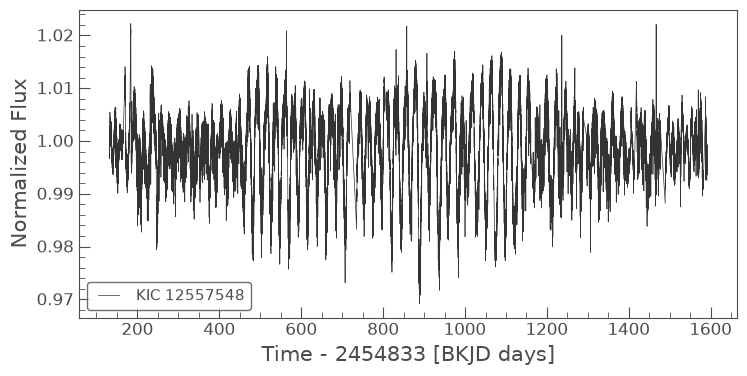

In [3]:
lc.normalize().remove_outliers().plot()

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

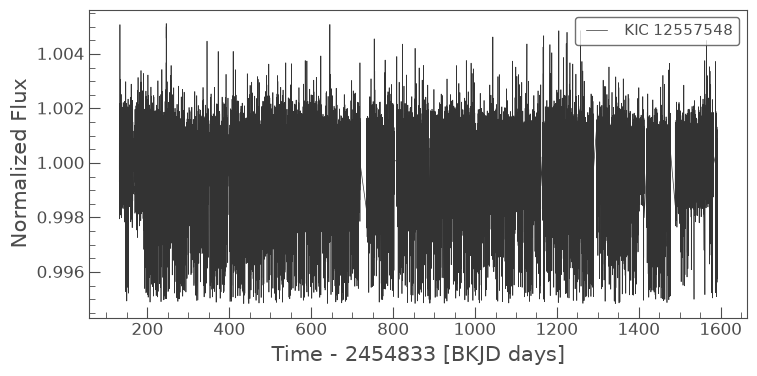

In [4]:
lc.flatten().remove_outliers().plot()

`period` contains 177509 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


<Axes: xlabel='Period [$\\mathrm{d}$]', ylabel='BLS Power'>

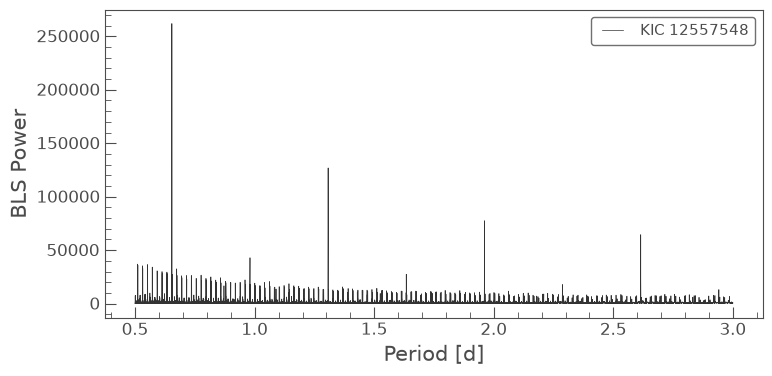

In [5]:
durations = np.linspace(0.02, 0.20, 150)

# 3. Run BLS for 12 to 72 hours (0.5 to 3.0 days)
bls = lc.to_periodogram(
    method="bls",
    minimum_period=0.5,   # 12 hours
    maximum_period=3.0,   # 72 hours
    duration=durations,
    frequency_factor=1000
)

bls.plot()

In [6]:
planet_b_period = bls.period_at_max_power
planet_b_t0 = bls.transit_time_at_max_power
planet_b_dur = bls.duration_at_max_power

# Check the value for period
planet_b_period

<Quantity 0.65354838 d>

<Axes: xlabel='Phase [JD]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

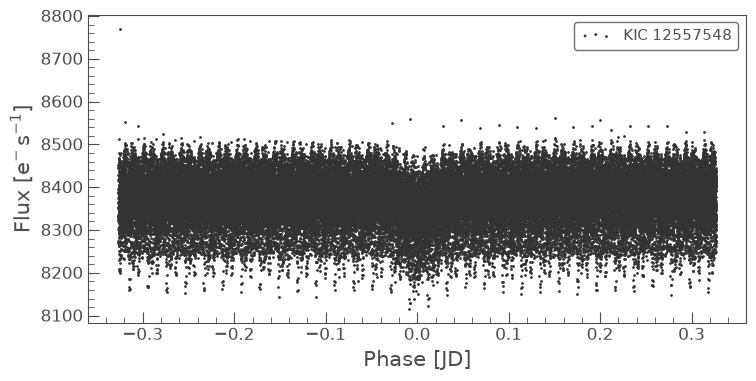

In [8]:
lc.fold(period = planet_b_period, epoch_time = planet_b_t0).scatter()

In [9]:
planet_b_model = bls.get_transit_model(period=planet_b_period,
                                       transit_time=planet_b_t0,
                                       duration=planet_b_dur)

<Axes: xlabel='Phase [JD]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

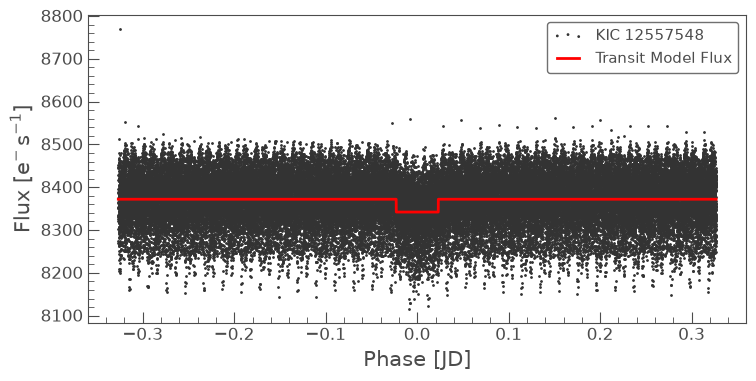

In [10]:
ax = lc.fold(planet_b_period, planet_b_t0).scatter()
planet_b_model.fold(planet_b_period, planet_b_t0).plot(ax=ax, c='r', lw=2)